# TP2 — Accidents routiers en Australie-Méridionale avec PySpark

**Contribution d’Alex Abdallah · ID16**

- **Exécution** · Le notebook a été rejoué du contrôle des 16 CSV au rechargement du modèle et aux
  mesures Spark finales. Les deux requêtes de contrôle concordent en RDD, DataFrame et Spark SQL.
- **Problèmes rencontrés** · Le découpage naïf des CSV décalait des colonnes contenant des virgules.
  La jointure sur les unités pouvait répéter les victimes d’un accident. Le champ `Day` décrit le
  jour de semaine et doit rester distinct de l’année, du mois et de l’heure. Plusieurs traitements
  rapatriaient des lignes qui pouvaient être agrégées dans Spark.
- **Modifications apportées** · Parseur CSV, contrôle des clés et rapprochement des deux tables.
  Comparaison des requêtes corrigées, des plans Spark, du nombre de cœurs et des partitions.
  Étude du volume et de la gravité par période, contexte et lieu. Comparaison de deux modèles
  sur une validation chronologique et sauvegarde d’un `PipelineModel` rechargeable.
- **Périmètre** · Une ligne de la table principale représente un accident enregistré. Les unités
  impliquées décrivent les accidents et permettent de contrôler les jointures.

| Partie | Question examinée |
|:---|:---|
| Chargement et contrôle | Les deux lectures interprètent-elles les mêmes fichiers et les mêmes clés ? |
| Analyse exploratoire | Comment les effectifs et la gravité varient-ils selon l’heure, les conditions et le lieu ? |
| Requêtes comparées | Comment retrouver les mêmes résultats dans les trois API ? |
| Modèle de gravité | Quel modèle classe le mieux les accidents sur l’année de validation ? |
| Export et benchmark | Peut-on recharger le modèle et vérifier l’effet des réglages Spark ? |

[Analyse de Rakesh Nain](https://medium.com/rakesh-nain/big-data-analysis-of-road-crash-data-using-pyspark-with-pyspark-tutorial-c78ff2c35588)
· [Instantané du code et des CSV](https://github.com/RakeshNain/Big-data-Analysis-of-Road-Crash-Data-using-PySpark-with-PySpark-Tutorial/tree/dab8e6466747903bf1e5bd21ce63fea31bfb6dcc)

## Data

### 1.1 Sources, clés et grain des observations

L’instantané couvre 2012 à 2019. Les deux tables décrivent les mêmes accidents à des niveaux
différents. Un fichier annuel existe pour chaque table. Les empreintes SHA-256 et les en-têtes
permettent de vérifier que le notebook reçoit l’instantané attendu.

| Table | Une ligne | Clé attendue |
|:---|:---|:---|
| `crash_data/` | Un accident enregistré | `REPORT_ID` |
| `units_data/` | Une unité impliquée, par exemple un véhicule, un piéton ou un obstacle | `REPORT_ID` et `Unit No` |

Le nombre de victimes d’un accident appartient au premier grain. La seconde table permet
d’étudier les équipements et les personnes associés à chaque unité. [Dictionnaire des champs](data/metadata-for-road-crash.pdf)

In [1]:
import csv
import hashlib
import json
import os
import re
import sys
from collections import Counter
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from statistics import median
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.functions import col

base = Path.cwd()
TP = next((p for p in (base, base / "TP2") if (p / "data" / "empreintes.json").is_file()), None)
if TP is None:
    raise FileNotFoundError("Lancer depuis la racine du dépôt ou depuis TP2/.")
output_root = os.environ.get("BIGDATA_OUTPUT_ROOT")
OUT = Path(output_root) / "TP2" if output_root else TP / "resultats_road_crash"
OUT.mkdir(parents=True, exist_ok=True)
DATA_ROOT = TP / "data"
hashes = json.loads((DATA_ROOT / "empreintes.json").read_text(encoding="utf-8"))
sources, manifest = {}, []

for folder in ("crash_data", "units_data"):
    files = sorted((DATA_ROOT / folder).glob("*.csv"))
    assert [f.name[:4] for f in files] == [str(y) for y in range(2012, 2020)], folder
    header = None
    for f in files:
        key = f.relative_to(DATA_ROOT).as_posix()
        with f.open("rb") as stream:
            sha = hashlib.file_digest(stream, "sha256").hexdigest()
        if sha != hashes.get(key):
            raise ValueError(f"Empreinte inattendue : {key}")
        with f.open(encoding="utf-8-sig", newline="") as stream:
            columns = next(csv.reader(stream))
        if header is None:
            header = columns
        assert header == columns, f"En-tête différent dans {key}"
        manifest.append({"fichier": key, "table": folder, "annee": int(f.name[:4]),
                         "octets": f.stat().st_size, "colonnes": len(columns), "sha256": sha})
    sources[folder] = (header, [f.resolve().as_uri() for f in files])
assert set(hashes) == {r["fichier"] for r in manifest}
manifest_pd = pd.DataFrame(manifest)
display(manifest_pd.groupby("table").agg(fichiers=("fichier", "size"),
                                          octets=("octets", "sum"), colonnes=("colonnes", "first")))

,fichiers,octets,colonnes
table,,,
crash_data,8,42545558,33
units_data,8,37698153,18


### 1.2 Ouvrir les données avec les deux lecteurs

Le lecteur RDD applique `csv.reader`. Il compte les lignes dont le découpage brut à la virgule
changerait le nombre de champs. Le lecteur DataFrame de Spark utilise le champ entre guillemets
en entier. La concordance des effectifs et les contrôles de clés complètent ce test de lecture.

In [2]:
os.environ["PYSPARK_PYTHON"] = sys.executable
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})


def demarrer_spark(coeurs):
    session = (SparkSession.builder.master(f"local[{coeurs}]").appName("TP2 - Accidents routiers")
               .config("spark.ui.enabled", "false")
               .config("spark.ui.showConsoleProgress", "false")
               .config("spark.driver.host", "127.0.0.1")
               .config("spark.driver.bindAddress", "127.0.0.1")
               .config("spark.driver.memory", "2g")
               .config("spark.sql.shuffle.partitions", "8").getOrCreate())
    session.sparkContext.setLogLevel("ERROR")
    return session


def lire_dataframe(session, dossier):
    _, paths = sources[dossier]
    return session.read.options(header=True, escape='"', mode="FAILFAST").csv(paths)


def lire_rdd(session, dossier):
    header, paths = sources[dossier]

    def parse_line(line):
        valeurs = next(csv.reader([line.removeprefix("\ufeff")], strict=True))
        if not valeurs or valeurs == header:
            return None
        if len(valeurs) != len(header):
            raise ValueError(f"Enregistrement CSV incomplet dans {dossier}.")
        return dict(zip(header, valeurs)), int(len(line.split(",")) != len(header))

    return session.sparkContext.textFile(",".join(paths)).map(parse_line).filter(lambda r: r is not None)


spark = demarrer_spark(4)
crash_raw, units_df = [lire_dataframe(spark, dossier).cache() for dossier in ("crash_data", "units_data")]
n_crash, n_units = crash_raw.count(), units_df.count()
parse_crash = lire_rdd(spark, "crash_data")
parse_units = lire_rdd(spark, "units_data").persist()
units_rdd = parse_units.keys()

audit_rows = []
for nom, parsed, attendu in [("Accidents", parse_crash, n_crash), ("Unités", parse_units, n_units)]:
    # Relever les décalages d’un découpage naïf pendant la lecture CSV valide.
    n, mal_decoupees = parsed.values().map(lambda f: (1, f)).fold(
        (0, 0), lambda a, b: (a[0] + b[0], a[1] + b[1]))
    assert n == attendu
    audit_rows.append({"Table": nom, "Effectif RDD": n, "Effectif DataFrame": attendu,
                       "Découpage naïf incorrect": mal_decoupees, "Part (%)": 100 * mal_decoupees / n})
audit_csv = pd.DataFrame(audit_rows).set_index("Table")
print(f"Spark {spark.version} · {spark.sparkContext.master} · {len(manifest)} fichiers vérifiés")
display(audit_csv.round(2))

Spark 4.0.1 · local[4] · 16 fichiers vérifiés


,Effectif RDD,Effectif DataFrame,Découpage naïf incorrect,Part (%)
Table,,,,
Accidents,127672,127672,21379,16.75
Unités,272591,272591,0,0.00


In [3]:
exemple = '2012-1,"Conseil, localité",1'
print("Découpage par virgule :", exemple.split(","))
print("Lecture CSV :", next(csv.reader([exemple])))
crash_raw.select("REPORT_ID", "Year", "Suburb", "CSEF Severity").orderBy("REPORT_ID").show(5, truncate=False)
units_df.select("REPORT_ID", "Unit No", "Unit Type", "Veh Reg State").orderBy("REPORT_ID", "Unit No").show(5, truncate=False)

Découpage par virgule : ['2012-1', '"Conseil', ' localité"', '1']
Lecture CSV : ['2012-1', 'Conseil, localité', '1']


+---------------------+----+---------------+-------------+
|REPORT_ID            |Year|Suburb         |CSEF Severity|
+---------------------+----+---------------+-------------+
|2012-1-21/08/2019    |2012|STEPNEY        |1: PDO       |
|2012-10-21/08/2019   |2012|PROSPECT       |1: PDO       |
|2012-100-21/08/2019  |2012|GLENSIDE       |2: MI        |
|2012-1000-21/08/2019 |2012|PARA HILLS WEST|2: MI        |
|2012-10000-21/08/2019|2012|NORTH ADELAIDE |1: PDO       |
+---------------------+----+---------------+-------------+
only showing top 5 rows


+-------------------+-------+------------------+-------------+
|REPORT_ID          |Unit No|Unit Type         |Veh Reg State|
+-------------------+-------+------------------+-------------+
|2012-1-21/08/2019  |01     |Pedal Cycle       |NULL         |
|2012-1-21/08/2019  |02     |Motor Cars - Sedan|SA           |
|2012-10-21/08/2019 |01     |Motor Cars - Sedan|SA           |
|2012-10-21/08/2019 |02     |Motor Cars - Sedan|SA           |
|2012-100-21/08/2019|01     |Motor Cars - Sedan|SA           |
+-------------------+-------+------------------+-------------+
only showing top 5 rows


**Lecture de l’audit.** Une virgule entre guillemets fait partie de la valeur du champ.
Conserver le bon nombre de colonnes maintient leur position et évite d’attribuer au mauvais
accident ou au mauvais indicateur une valeur lue sur la ligne.

## Prétraitement

### 2.1 Vérifier les liens entre les accidents et les unités

On vérifie l’unicité des clés, l’absence d’unité orpheline et la cohérence des compteurs.
Réunir les unités par `REPORT_ID` permet de retrouver à la fois le nombre d’unités et le
nombre de victimes déclaré dans la ligne de l’accident. Ce rapprochement protège ensuite
l’analyse contre un changement involontaire de grain.

In [4]:
assert not crash_raw.where(col("REPORT_ID").isNull()).limit(1).count()
assert not units_df.where(col("REPORT_ID").isNull() | col("Unit No").isNull()).limit(1).count()
assert not crash_raw.groupBy("REPORT_ID").count().where("count > 1").limit(1).count()
assert not units_df.groupBy("REPORT_ID", "Unit No").count().where("count > 1").limit(1).count()
assert not units_df.join(crash_raw.select("REPORT_ID"), "REPORT_ID", "left_anti").limit(1).count()

severity_labels = {"1: PDO": "Matériel seul", "2: MI": "Blessures légères",
                   "3: SI": "Blessures graves", "4: Fatal": "Mortel"}
severity_order = list(severity_labels)
assert {r[0] for r in crash_raw.select("CSEF Severity").distinct().collect()} == set(severity_order)
numeriques = ["Year", "Total Units", "Total Cas", "Total Fats", "Total SI", "Total MI"]
crash_typed = (crash_raw.withColumns({nom: F.expr(f"try_cast(`{nom}` as int)") for nom in numeriques})
               .withColumn("label", col("CSEF Severity").isin("3: SI", "4: Fatal").cast("double"))
               .cache())
assert crash_typed.dropna(subset=numeriques).count() == n_crash
assert {r[0] for r in crash_typed.select("Year").distinct().collect()} == set(range(2012, 2020))
assert not crash_typed.where(col("Total Cas") != col("Total Fats") + col("Total SI") + col("Total MI")).limit(1).count()

# Ramener les comptes d’unités et de victimes au grain de l’accident avant la comparaison.
calc_unites = units_df.groupBy("REPORT_ID").agg(F.count("*").alias("unites_calculees"),
                  F.sum(F.expr("try_cast(`No Of Cas` as int)")).alias("victimes_calculees"))
joint = crash_typed.select("REPORT_ID", "Total Units", "Total Cas").join(calc_unites, "REPORT_ID", "left")
incoherents = joint.where((~col("Total Units").eqNullSafe(col("unites_calculees"))) |
                         (~col("Total Cas").eqNullSafe(col("victimes_calculees")))).count()
assert incoherents == 0
crash_raw.unpersist()
crash_df = crash_typed

summary = crash_df.agg(F.count("*").alias("accidents"), F.sum("Total Units").alias("unites"),
                        F.sum("Total Cas").alias("victimes"), F.sum("Total Fats").alias("deces"),
                        F.sum("Total SI").alias("blesses_graves"), F.sum("Total MI").alias("blesses_legers")).first().asDict()
assert summary["unites"] == n_units
display(pd.DataFrame([summary]))
print(f"Rapprochement conforme pour les {n_crash:,} accidents.")

,accidents,unites,victimes,deces,blesses_graves,blesses_legers
0,127672,272591,53255,781,5744,46730


Rapprochement conforme pour les 127,672 accidents.


### 2.2 Préparer les champs d’analyse

`Time` est lu au format 12 heures puis converti en une heure de 0 à 23. La variable `label`
vaut 1 pour les accidents graves ou mortels. L’indicateur `mortel` sépare les accidents mortels
du nombre de décès, qui peut être supérieur à un pour le même accident.

In [5]:
contexte = (crash_df
    .withColumn("heure", F.hour(F.try_to_timestamp(F.upper(F.trim("Time")), F.lit("hh:mm a"))))
    .withColumn("vitesse_limite", F.expr("try_cast(`Area Speed` as int)"))
    .withColumn("mortel", (col("CSEF Severity") == "4: Fatal").cast("int"))
    .cache())
qualite = contexte.agg(
    F.sum(col("heure").isNull().cast("int")).alias("heures_illisibles"),
    F.sum((col("vitesse_limite").isNull() | (col("vitesse_limite") <= 0)).cast("int")).alias("vitesse_indisponible"),
    F.sum(col("label").cast("int")).alias("accidents_graves_ou_mortels"),
    F.sum("mortel").alias("accidents_mortels"),
).first().asDict()
print("Indicateurs de qualité et de gravité")
display(pd.DataFrame([qualite]))

Indicateurs de qualité et de gravité


,heures_illisibles,vitesse_indisponible,accidents_graves_ou_mortels,accidents_mortels
0,0,0,5597,722


## EDA

### 3.1 Répartition des unités et agrégations RDD

On partitionne les unités d’après la colonne d’immatriculation `Veh Reg State`. La partition
`SA` contient les unités immatriculées dans l’État. L’autre partition reçoit toutes les autres
valeurs. La moyenne par sexe déclaré combine des sommes et des effectifs avec `reduceByKey`.
Pour les millésimes, `takeOrdered` ne récupère que trois résultats par extrême.

In [6]:
repartitionne = (units_rdd.map(lambda row: (row["Veh Reg State"], 1))
                 .partitionBy(2, lambda etat: 0 if etat == "SA" else 1))
tailles = repartitionne.mapPartitions(lambda lignes: [sum(1 for _ in lignes)]).collect()
assert sum(tailles) == n_units
display(pd.Series(tailles, index=["SA", "Hors SA ou inconnu"], name="Unités").to_frame())

ages = (units_rdd.filter(lambda r: r["Age"].isascii() and r["Age"].isdigit()
                         and r["Sex"] not in {"", "Unknown"})
        .map(lambda r: (r["Sex"], (int(r["Age"]), 1)))
        .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1])))
display(pd.DataFrame([(sexe, n, somme / n) for sexe, (somme, n) in sorted(ages.collect())],
                     columns=["Sexe renseigné", "Effectif", "Âge moyen"]).round(2))

millesimes = (units_rdd.filter(lambda r: r["Veh Year"].isascii() and r["Veh Year"].isdigit())
              .map(lambda r: (int(r["Veh Year"]), r["Veh Reg State"], r["Unit Type"])))
print("Trois unités aux millésimes les plus anciens :", millesimes.takeOrdered(3))
print("Trois unités aux millésimes les plus récents :", millesimes.takeOrdered(3, key=lambda r: -r[0]))
parse_units.unpersist()

,Unités
SA,218366
Hors SA ou inconnu,54225


,Sexe renseigné,Effectif,Âge moyen
0,Female,85603,40.08
1,Male,131892,40.80


Trois unités aux millésimes les plus anciens : [(1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle'), (1900, 'SA', 'Motor Cycle')]


Trois unités aux millésimes les plus récents : [(2019, 'SA', 'Station Wagon'), (2019, 'SA', 'OMNIBUS'), (2019, 'SA', 'Motor Cars - Sedan')]


PythonRDD[48] at RDD at PythonRDD.scala:56

**Lecture des partitions.** La catégorie `SA` concentre environ 80 % des unités. Ce choix de
partitionnement illustre un déséquilibre de charge. Les moyennes d’âge concernent les unités
dont ces deux champs sont renseignés. Les millésimes sont ceux déclarés dans les CSV.

### 3.2 Gravité et signalements d’alcool ou de stupéfiants

Les accidents sont répartis en quatre groupes exclusifs à partir des deux indicateurs `Y`.
On garde les quatre degrés de gravité et on compare leurs parts à l’intérieur de chaque groupe.
Un champ vide signifie absence de signalement dans cet instantané.

,groupe,CSEF Severity,count,total_groupe,part_pct
0,Alcool Y sans stupéfiants Y,1: PDO,2108,3681,57.27
1,Alcool Y sans stupéfiants Y,2: MI,1092,3681,29.67
2,Alcool Y sans stupéfiants Y,3: SI,384,3681,10.43
3,Alcool Y sans stupéfiants Y,4: Fatal,97,3681,2.64
4,Aucun signalement Y,1: PDO,82430,122137,67.49
5,Aucun signalement Y,2: MI,35099,122137,28.74
6,Aucun signalement Y,3: SI,4100,122137,3.36
7,Aucun signalement Y,4: Fatal,508,122137,0.42
8,Deux indicateurs Y,1: PDO,36,298,12.08
9,Deux indicateurs Y,2: MI,151,298,50.67


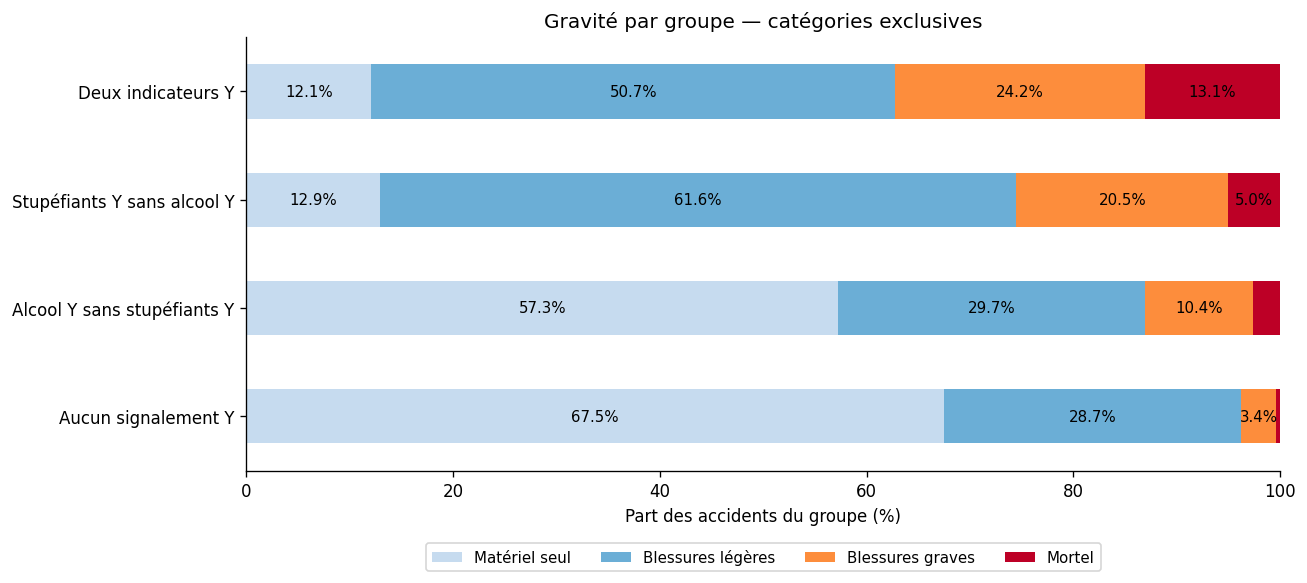

In [7]:
from pyspark.sql import Window
alcohol_y = F.coalesce(col("DUI Involved") == "Y", F.lit(False))
drugs_y = F.coalesce(col("Drugs Involved") == "Y", F.lit(False))
labeled = crash_df.withColumn("groupe",
    F.when(alcohol_y & drugs_y, "Deux indicateurs Y")
     .when(alcohol_y, "Alcool Y sans stupéfiants Y")
     .when(drugs_y, "Stupéfiants Y sans alcool Y")
     .otherwise("Aucun signalement Y"))
exclusive_labels = ["Aucun signalement Y", "Alcool Y sans stupéfiants Y",
                    "Stupéfiants Y sans alcool Y", "Deux indicateurs Y"]
grid = (spark.createDataFrame([(g,) for g in exclusive_labels], ["groupe"])
    .crossJoin(spark.createDataFrame([(s,) for s in severity_order], ["CSEF Severity"])))
exclusive_stats = (grid.join(labeled.groupBy("groupe", "CSEF Severity").count(),
                            ["groupe", "CSEF Severity"], "left").fillna(0, ["count"])
    .withColumn("total_groupe", F.sum("count").over(Window.partitionBy("groupe")))
    .withColumn("part_pct", F.when(col("total_groupe") > 0, 100 * col("count") / col("total_groupe"))))
exclusive_pd = exclusive_stats.toPandas()
assert int(exclusive_pd["count"].sum()) == n_crash
assert all(abs(x - 100) < 1e-8 for x in exclusive_pd.groupby("groupe")["part_pct"].sum())
display(exclusive_pd.sort_values(["groupe", "CSEF Severity"]).round(2))
table = exclusive_pd.pivot(index="groupe", columns="CSEF Severity", values="part_pct").reindex(index=exclusive_labels, columns=severity_order)
table.columns = [severity_labels[s] for s in table.columns]
fig, ax = plt.subplots(figsize=(11, 5))
table.plot.barh(stacked=True, ax=ax, color=["#c6dbef", "#6baed6", "#fd8d3c", "#bd0026"])
for container in ax.containers:
    ax.bar_label(container, labels=[f"{v:.1f}%" if v >= 3 else "" for v in container.datavalues], label_type="center", fontsize=9)
ax.set(xlim=(0, 100), xlabel="Part des accidents du groupe (%)", ylabel="", title="Gravité par groupe — catégories exclusives")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=9)
fig.tight_layout()
fig.savefig(OUT / "03_gravite_groupes_exclusifs.png", bbox_inches="tight")
plt.show()

**Lecture des proportions.** Pour lire une part d’accidents mortels, on rapporte les accidents
mortels au nombre d’accidents du groupe correspondant. Les groupes avec signalements sont de
taille plus faible. Les différences décrivent les accidents enregistrés et le signalement
peut dépendre des circonstances de l’accident.

### 3.3 Évolution annuelle et types d’accidents

La courbe de volume compte les accidents enregistrés. La part de cas graves ou mortels utilise
le nombre d’accidents de l’année comme dénominateur. Pour les types d’accidents, on lit à la
fois les décès cumulés et les décès pour 1 000 accidents de chaque type.

,Year,accidents,victimes,deces,graves_ou_mortels,part_graves_ou_mortels_pct
0,2012,22829,7479,94,723,3.17
1,2013,16675,7177,97,755,4.53
2,2014,16162,6982,108,690,4.27
3,2015,15431,6660,102,753,4.88
4,2016,16775,6565,86,651,3.88
5,2017,13237,6237,100,626,4.73
6,2018,13599,6124,80,560,4.12
7,2019,12964,6031,114,839,6.47


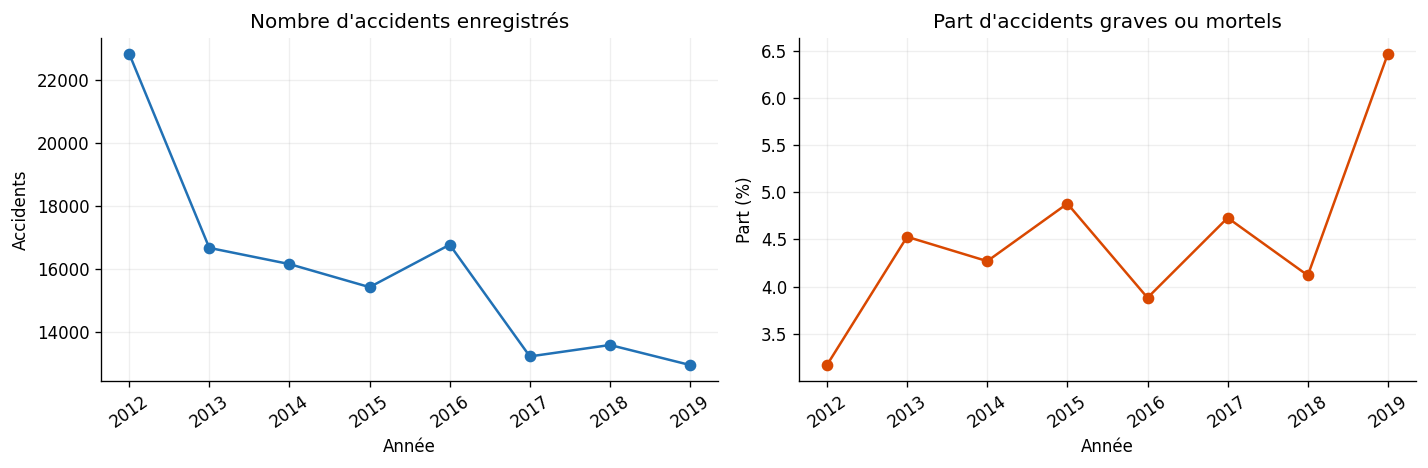

In [8]:
annual = (crash_typed.groupBy("Year").agg(F.count("*").alias("accidents"),
    F.sum("Total Cas").alias("victimes"), F.sum("Total Fats").alias("deces"),
    F.sum(col("CSEF Severity").isin("3: SI", "4: Fatal").cast("int")).alias("graves_ou_mortels"))
    .withColumn("part_graves_ou_mortels_pct", 100 * col("graves_ou_mortels") / col("accidents"))
    .orderBy("Year"))
annual_pd = annual.toPandas()
display(annual_pd.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(annual_pd["Year"], annual_pd["accidents"], marker="o", color="#2171b5")
axes[0].set(title="Nombre d'accidents enregistrés", xlabel="Année", ylabel="Accidents")
axes[1].plot(annual_pd["Year"], annual_pd["part_graves_ou_mortels_pct"], marker="o", color="#d94801")
axes[1].set(title="Part d'accidents graves ou mortels", xlabel="Année", ylabel="Part (%)")
for ax in axes:
    ax.set_xticks(annual_pd["Year"])
    ax.tick_params(axis="x", rotation=35)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUT / "04_evolution_annuelle.png", bbox_inches="tight")
plt.show()

,Crash Type,accidents,deces,deces_pour_1000
0,Hit Fixed Object,19365,245,12.65
1,Head On,2086,136,65.20
2,Hit Pedestrian,2848,109,38.27
3,Roll Over,5304,93,17.53
4,Right Angle,24236,82,3.38
5,Rear End,37218,33,0.89
6,Side Swipe,13111,30,2.29
7,Right Turn,10083,26,2.58
8,Hit Parked Vehicle,9148,10,1.09
9,Hit Animal,2042,7,3.43


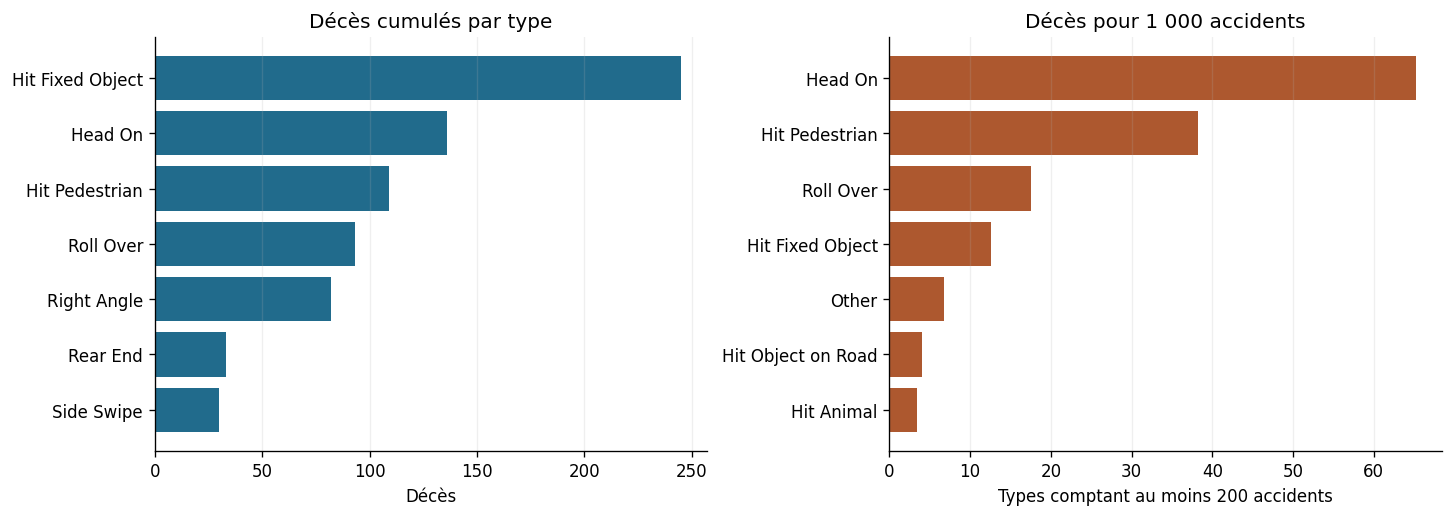

In [9]:
types = (contexte.groupBy("Crash Type").agg(F.count("*").alias("accidents"), F.sum("Total Fats").alias("deces"))
         .withColumn("deces_pour_1000", 1000 * col("deces") / col("accidents")))
par_type = types.orderBy(F.desc("deces"), "Crash Type").toPandas()
assert par_type["accidents"].sum() == n_crash
assert par_type["deces"].sum() == summary["deces"]
display(par_type.round(2))

a = par_type.head(7).sort_values("deces")
b = par_type.loc[par_type["accidents"].ge(200)].nlargest(7, "deces_pour_1000").sort_values("deces_pour_1000")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
axes[0].barh(a["Crash Type"], a["deces"], color="#216b8c")
axes[0].set(title="Décès cumulés par type", xlabel="Décès")
axes[1].barh(b["Crash Type"], b["deces_pour_1000"], color="#ad582f")
axes[1].set(title="Décès pour 1 000 accidents", xlabel="Types comptant au moins 200 accidents")
for ax in axes:
    ax.grid(axis="x", alpha=0.2)
fig.savefig(OUT / "01_deces_par_type.png", bbox_inches="tight")
plt.show()

**Lecture du classement.** Le nombre cumulé dépend du volume d’accidents de chaque type.
Un type fréquent peut contribuer à beaucoup de décès avec un taux plus faible. Le filtre
de 200 accidents dans la figure de droite limite le classement aux types bien représentés.

### 3.4 Quand surviennent les accidents ?

On agrège les volumes par jour de semaine et par heure locale. Le second tableau rapproche
gravité et heure. À cette échelle, une heure fréquente et une heure où les cas graves sont
proportionnellement nombreux donnent deux lectures distinctes des mêmes observations.

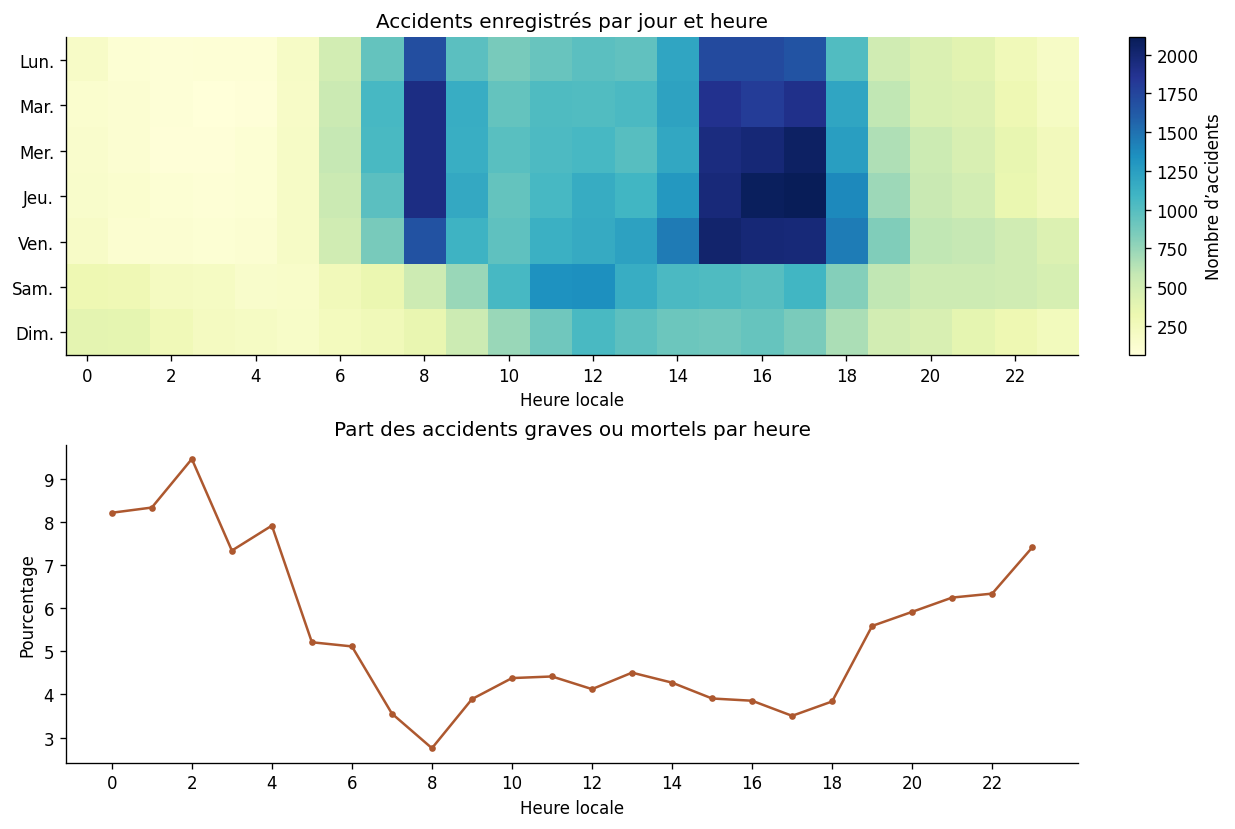

Volume maximal à 17 h : 11,642 accidents.
Part grave maximale à 2 h : 9.47 % sur 940 accidents.


In [10]:
jours = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
libelles = ["Lun.", "Mar.", "Mer.", "Jeu.", "Ven.", "Sam.", "Dim."]
calendrier = (contexte.dropna(subset=["heure"]).groupBy("Day", "heure").agg(
    F.count("*").alias("accidents"), F.sum(col("label").cast("long")).alias("graves"))).toPandas()
assert int(calendrier["accidents"].sum()) + qualite["heures_illisibles"] == n_crash
grille = calendrier.pivot(index="Day", columns="heure", values="accidents").reindex(index=jours, columns=range(24))
par_heure = calendrier.groupby("heure")[['accidents', 'graves']].sum()
par_heure["graves_pct"] = 100 * par_heure["graves"] / par_heure["accidents"]

fig, axes = plt.subplots(2, 1, figsize=(10.2, 6.8), layout="constrained")
im = axes[0].imshow(grille.fillna(0), cmap="YlGnBu", interpolation="nearest", aspect="auto")
axes[0].set(title="Accidents enregistrés par jour et heure", yticks=range(7), yticklabels=libelles)
fig.colorbar(im, ax=axes[0], label="Nombre d’accidents")
axes[1].plot(par_heure.index, par_heure["graves_pct"], color="#ad582f", marker="o", ms=3)
axes[1].set(title="Part des accidents graves ou mortels par heure", ylabel="Pourcentage")
for ax in axes:
    ax.set(xlabel="Heure locale", xticks=range(0, 24, 2))
fig.savefig(OUT / "05_gravite_par_heure.png", bbox_inches="tight")
plt.show()
pointe = int(par_heure["accidents"].idxmax())
forte_part = int(par_heure["graves_pct"].idxmax())
print(f"Volume maximal à {pointe} h : {par_heure.loc[pointe, 'accidents']:,} accidents.")
print(f"Part grave maximale à {forte_part} h : {par_heure.loc[forte_part, 'graves_pct']:.2f} % "
      f"sur {par_heure.loc[forte_part, 'accidents']:,} accidents.")

### 3.5 Conditions de route et vitesse limite

Les catégories conservent leurs effectifs. Le graphique de vitesse retient les limites
renseignées avec au moins 200 accidents. Les intervalles de Wilson à 95 % montrent la
précision de chaque proportion observée sous un modèle binomial. La vitesse renseignée
correspond à la limite du secteur.

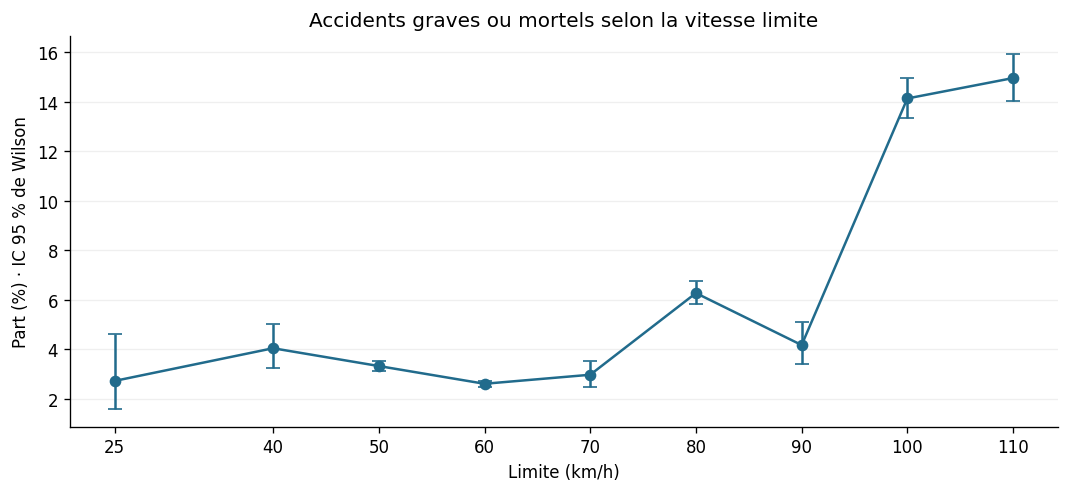

,vitesse_limite,accidents,graves,part_grave_pct
0,25,476,13,2.73
1,40,1852,75,4.05
2,50,34244,1141,3.33
3,60,61035,1597,2.62
4,70,4026,120,2.98
5,80,11013,691,6.27
6,90,2106,88,4.18
7,100,7413,1047,14.12
8,110,5359,801,14.95


,Condition,Modalité,accidents,graves,part_grave_pct
0,DayNight,Daylight,98724,3890,3.94
1,DayNight,Night,28948,1707,5.90
2,Road Surface,Unknown,14,1,7.14
3,Road Surface,Unsealed,3507,480,13.69
4,Road Surface,Sealed,124151,5116,4.12
5,Weather Cond,Not Raining,115956,5145,4.44
6,Weather Cond,Raining,11268,422,3.75
7,Weather Cond,Unknown,448,30,6.70
8,Stats Area,1 City,6940,184,2.65
9,Stats Area,3 Country,19915,2314,11.62


In [11]:
def taux_graves(t, colonne):
    return (t.groupBy(colonne)
            .agg(F.count("*").alias("accidents"), F.sum(col("label").cast("long")).alias("graves"))
            .withColumn("part_grave_pct", 100 * col("graves") / col("accidents")))


vitesses = (taux_graves(contexte.where(col("vitesse_limite") > 0), "vitesse_limite")
            .where("accidents >= 200").orderBy("vitesse_limite").toPandas())
n = vitesses["accidents"].to_numpy()
p = vitesses["graves"].to_numpy() / n
# L’intervalle de Wilson tient compte du nombre d’accidents dans chaque groupe.
z = 1.96
denominateur = 1 + z**2 / n
centre = (p + z**2 / (2 * n)) / denominateur
largeur = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominateur
fig, ax = plt.subplots(figsize=(8.8, 4.0), layout="constrained")
positions = vitesses["vitesse_limite"].to_numpy()
erreur = 100 * np.maximum(0, np.vstack((p-centre+largeur, centre+largeur-p)))
ax.errorbar(positions, p*100, yerr=erreur,
            marker="o", capsize=4, color="#216b8c")
ax.set(title="Accidents graves ou mortels selon la vitesse limite", xlabel="Limite (km/h)",
       ylabel="Part (%) · IC 95 % de Wilson", xticks=positions)
ax.grid(axis="y", alpha=0.2)
fig.savefig(OUT / "07_gravite_vitesse.png", bbox_inches="tight")
plt.show()
display(vitesses.round(2))

conditions_pd = pd.concat([taux_graves(contexte, champ).toPandas()
    .rename(columns={champ: "Modalité"}).assign(Condition=champ)
    for champ in ("DayNight", "Road Surface", "Weather Cond", "Stats Area")], ignore_index=True)
assert conditions_pd.groupby("Condition")["accidents"].sum().eq(n_crash).all()
display(conditions_pd[["Condition", "Modalité", "accidents", "graves", "part_grave_pct"]].round(2))

**Lecture des conditions.** Ces taux portent sur les accidents enregistrés dans chaque
catégorie. Les limites de vitesse, la luminosité, le type de chaussée et la zone peuvent
varier ensemble. Le tableau donne les effectifs pour interpréter un écart de proportion.

### 3.6 Unités impliquées et permis renseignés

La jointure transmet la gravité de l’accident à chacune de ses unités. Le dénominateur de
ce tableau est donc le nombre d’unités de la catégorie. Les catégories vides ont été
regroupées sous « Non renseigné » et les catégories rares sont conservées dans les agrégats.

In [12]:
situations_unites = units_df.join(contexte.select("REPORT_ID", "label"), "REPORT_ID", "inner")
permis = F.trim(col("Licence Type"))
par_permis = (taux_graves(situations_unites.withColumn("permis", F.coalesce(F.nullif(permis, F.lit("")),
                      F.lit("Non renseigné"))), "permis").orderBy(F.desc("accidents"))).toPandas()
par_unite = taux_graves(situations_unites, "Unit Type").orderBy(F.desc("accidents")).toPandas()
assert int(par_permis["accidents"].sum()) == int(par_unite["accidents"].sum()) == n_units
display(par_permis.rename(columns={"accidents": "unités", "graves": "unités liées à un cas grave"}).round(2))
display(par_unite.head(10).rename(columns={"accidents": "unités", "graves": "unités liées à un cas grave"}).round(2))

,permis,unités,unités liées à un cas grave,part_grave_pct
0,Full,168865,5667,3.36
1,Non renseigné,48695,3785,7.77
2,Unknown,22695,544,2.40
3,Provisional 1,15657,505,3.23
4,Provisional 2,8663,299,3.45
5,Unlicenced,3926,383,9.76
6,Learners,2432,174,7.15
7,Probationary,1162,49,4.22
8,Disqualified,428,51,11.92
9,Conditional,68,4,5.88


,Unit Type,unités,unités liées à un cas grave,part_grave_pct
0,Motor Cars - Sedan,135210,3694,2.73
1,Station Wagon,44209,1353,3.06
2,Utility,20800,814,3.91
3,Other Fixed Obstruction,10074,630,6.25
4,Tree,7640,978,12.80
5,Pedal Cycle,7194,591,8.22
6,Motor Cycle,6373,1106,17.35
7,RIGID TRUCK LGE GE 4.5T,5722,161,2.81
8,Panel Van,5125,142,2.77
9,Motor Vehicle - Type Unknown,4925,86,1.75


### 3.7 Où se concentrent les accidents enregistrés ?

Le dictionnaire décrit `ACCLOC_X` et `ACCLOC_Y` comme des coordonnées Lambert GDA94 en mètres.
On les arrondit dans une grille de 25 km et on collecte les effectifs par cellule. Les axes
sont exprimés dans la projection du fichier. Les accidents sans coordonnées restent dans
les autres analyses. [Dictionnaire des champs, projection à la page 2](data/metadata-for-road-crash.pdf#page=2)

123,801 accidents géolocalisés sur 127,672 · 552 cellules de 25 km.


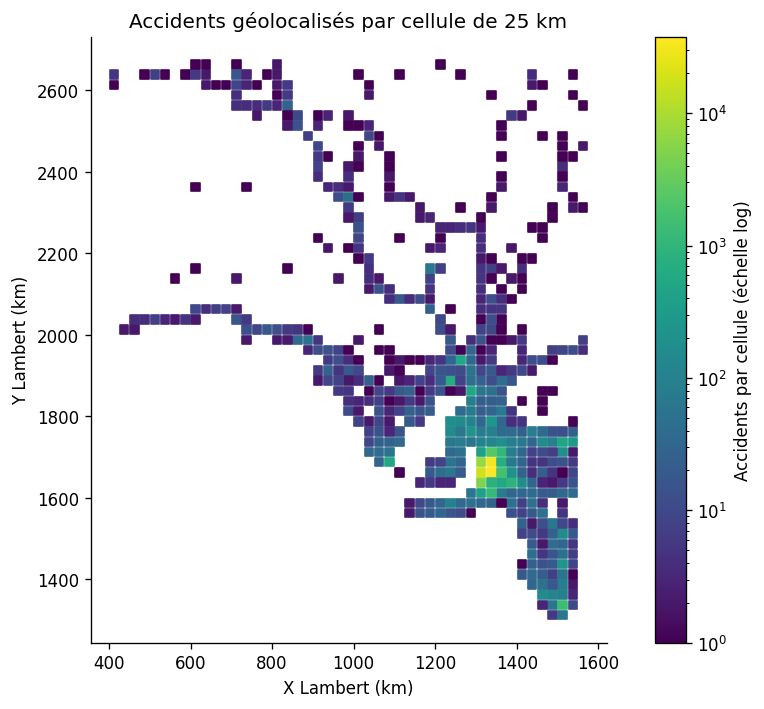

In [13]:
from matplotlib.colors import LogNorm

pas = 25_000
points = contexte.select(F.expr("try_cast(ACCLOC_X as double)").alias("x"),
                         F.expr("try_cast(ACCLOC_Y as double)").alias("y"), "label").dropna()
cellules = (points.withColumn("gx", F.floor(col("x") / pas)).withColumn("gy", F.floor(col("y") / pas))
            .groupBy("gx", "gy").agg(F.count("*").alias("accidents"),
                                      F.sum(col("label").cast("long")).alias("graves"))).toPandas()
n_geom = int(cellules["accidents"].sum())
assert 0 < n_geom <= n_crash
print(f"{n_geom:,} accidents géolocalisés sur {n_crash:,} · {len(cellules)} cellules de 25 km.")
fig, ax = plt.subplots(figsize=(7.3, 5.8), layout="constrained")
points_agg = ax.scatter((cellules["gx"]+0.5)*pas/1000, (cellules["gy"]+0.5)*pas/1000,
                        c=cellules["accidents"], norm=LogNorm(vmin=1), cmap="viridis", marker="s", s=26)
fig.colorbar(points_agg, ax=ax, label="Accidents par cellule (échelle log)")
ax.set(title="Accidents géolocalisés par cellule de 25 km", xlabel="X Lambert (km)",
       ylabel="Y Lambert (km)", aspect="equal")
fig.savefig(OUT / "08_localisation_agregee.png", bbox_inches="tight")
plt.show()

## Transformation

### 4.1 Comparer la même projection à Adelaide

Pour chaque unité d’un accident enregistré à Adelaide, on sélectionne les mêmes colonnes
dans les trois API. Le jour de semaine, le mois, l’année et l’heure gardent chacun leur
signification. Le contrôle `exceptAll` des deux côtés préserve les multiplicités.

In [14]:
crash_df.createOrReplaceTempView("accidents")
units_df.createOrReplaceTempView("unites")
c_fields = ["REPORT_ID", "Suburb", "Year", "Month", "Day", "Time", "Total Cas"]
u_fields = ["REPORT_ID", "Unit No", "No Of Cas", "Sex", "Age", "Licence Type"]
c_pairs = crash_df.select(*c_fields).rdd.map(lambda r: (r.REPORT_ID, r.asDict()))
u_pairs = units_df.select(*u_fields).rdd.map(lambda r: (r.REPORT_ID, r.asDict()))

adelaide_df = (crash_df.alias("c").join(units_df.alias("u"), "REPORT_ID")
    .where(col("c.Suburb") == "ADELAIDE")
    .select("REPORT_ID", "u.Unit No", "c.Year", "c.Month", "c.Day", "c.Time", "u.Sex", "u.Age",
            "u.Licence Type", col("u.No Of Cas").cast("int").alias("victimes_unite"),
            col("c.Total Cas").alias("victimes_accident")))
adelaide_sql = spark.sql("""
    SELECT c.REPORT_ID, u.`Unit No`, c.Year, c.Month, c.Day, c.Time, u.Sex, u.Age, u.`Licence Type`,
           CAST(u.`No Of Cas` AS INT) AS victimes_unite, c.`Total Cas` AS victimes_accident
    FROM accidents c JOIN unites u ON c.REPORT_ID = u.REPORT_ID
    WHERE c.Suburb = 'ADELAIDE'
""")

def projeter_unite(record):
    key, (c, u) = record
    victimes_unite = None if u["No Of Cas"] is None else int(u["No Of Cas"])
    return (key, u["Unit No"], c["Year"], c["Month"], c["Day"], c["Time"], u["Sex"], u["Age"],
            u["Licence Type"], victimes_unite, c["Total Cas"])


adelaide_rdd = (c_pairs.filter(lambda kv: kv[1]["Suburb"] == "ADELAIDE")
                .join(u_pairs).map(projeter_unite))
adelaide_rdd_df = spark.createDataFrame(adelaide_rdd, adelaide_df.schema)

def assert_same_rows(left, right):
    assert left.dtypes == right.dtypes, "Colonnes ou types différents"
    assert not left.exceptAll(right).limit(1).count(), "Ligne excédentaire à gauche"
    assert not right.exceptAll(left).limit(1).count(), "Ligne excédentaire à droite"


assert_same_rows(adelaide_df, adelaide_sql)
assert_same_rows(adelaide_df, adelaide_rdd_df)
print("RDD, DataFrame et SQL : mêmes lignes pour Adelaide.")
adelaide_df.orderBy("REPORT_ID", "Unit No").show(8, truncate=False)

RDD, DataFrame et SQL : mêmes lignes pour Adelaide.


+---------------------+-------+----+-----+---------+--------+------+---+------------+--------------+-----------------+
|REPORT_ID            |Unit No|Year|Month|Day      |Time    |Sex   |Age|Licence Type|victimes_unite|victimes_accident|
+---------------------+-------+----+-----+---------+--------+------+---+------------+--------------+-----------------+
|2012-10007-21/08/2019|01     |2012|June |Wednesday|05:30 pm|Female|036|Unknown     |0             |0                |
|2012-10007-21/08/2019|02     |2012|June |Wednesday|05:30 pm|Male  |XXX|Unknown     |0             |0                |
|2012-10027-21/08/2019|01     |2012|June |Thursday |02:45 pm|Male  |062|Full        |0             |0                |
|2012-10027-21/08/2019|02     |2012|June |Thursday |02:45 pm|Female|020|Full        |0             |0                |
|2012-10040-21/08/2019|01     |2012|June |Thursday |05:24 pm|Male  |049|Full        |0             |1                |
|2012-10040-21/08/2019|02     |2012|June |Thursd

### 4.2 Compter les accidents avec au moins une unité sans permis

La requête utilise la valeur source `Unlicenced` et sélectionne les accidents qui ont
au moins une unité correspondante. En RDD on dédoublonne les clés avant la jointure.
Le DataFrame applique `left_semi` et SQL exprime l’existence avec `EXISTS`.
Les victimes sont ensuite sommées au niveau des accidents par localité.

In [15]:
SQL_SANS_PERMIS = """
    SELECT c.Suburb, count(*) AS accidents, sum(c.`Total Cas`) AS victimes
    FROM accidents c WHERE EXISTS (
        SELECT 1 FROM unites u WHERE u.REPORT_ID = c.REPORT_ID AND u.`Licence Type` = 'Unlicenced'
    ) GROUP BY c.Suburb
"""


def sans_permis_df(accidents, unites):
    ids = unites.where(col("Licence Type") == "Unlicenced").select("REPORT_ID")
    return accidents.join(ids, "REPORT_ID", "left_semi").groupBy("Suburb").agg(
        F.count("*").alias("accidents"), F.sum("Total Cas").alias("victimes"))


def sans_permis_rdd(accidents, unites, partitions=8):
    a = accidents.select("REPORT_ID", "Suburb", "Total Cas").rdd.map(lambda r: (r[0], (r[1], r[2])))
    u = (unites.select("REPORT_ID", "Licence Type").rdd.filter(lambda r: r[1] == "Unlicenced")
         .map(lambda r: (r[0], 1)).reduceByKey(lambda x, y: 1, partitions))
    return (a.join(u, partitions).map(lambda rec: (rec[1][0][0], (1, rec[1][0][1])))
            .reduceByKey(lambda x, y: (x[0] + y[0], x[1] + y[1]), partitions)
            .map(lambda rec: (rec[0], rec[1][0], rec[1][1])))


unlicensed_corrected = sans_permis_df(crash_df, units_df)
unlicensed_corrected_sql = spark.sql(SQL_SANS_PERMIS)
unlicensed_rdd_df = spark.createDataFrame(sans_permis_rdd(crash_df, units_df), unlicensed_corrected.schema)
assert_same_rows(unlicensed_corrected, unlicensed_corrected_sql)
assert_same_rows(unlicensed_corrected, unlicensed_rdd_df)
reference_api = Counter(map(tuple, unlicensed_corrected.collect()))
sans_permis = units_df.where(col("Licence Type") == "Unlicenced").select("REPORT_ID")
original_total = crash_df.join(sans_permis, "REPORT_ID").agg(F.sum("Total Cas")).first()[0]
corrected_total = sum(victimes * n for (_, _, victimes), n in reference_api.items())
print(f"Jointure directe : {original_total:,} victimes · comptage par accident : {corrected_total:,} victimes.")
unlicensed_corrected.orderBy(F.desc("victimes"), "Suburb").show(10, truncate=False)

Jointure directe : 2,072 victimes · comptage par accident : 2,053 victimes.


+--------------+---------+--------+
|Suburb        |accidents|victimes|
+--------------+---------+--------+
|ADELAIDE      |149      |42      |
|SALISBURY     |40       |30      |
|PROSPECT      |48       |27      |
|INGLE FARM    |32       |22      |
|MORPHETT VALE |49       |20      |
|DRY CREEK     |19       |19      |
|MURRAY BRIDGE |30       |19      |
|SALISBURY EAST|30       |19      |
|MAWSON LAKES  |36       |17      |
|NORTH ADELAIDE|42       |17      |
+--------------+---------+--------+
only showing top 10 rows


**Lecture de la correction.** La différence mesure les victimes répétées par la jointure
directe. Une localité du résultat porte désormais un total d’accidents uniques répondant
à la condition et la somme de leurs victimes. Ce tableau sert de référence au benchmark.

## ML

### 5.1 Définir la cible et séparer les périodes

Un accident est classé grave lorsque `CSEF Severity` vaut `3: SI` ou `4: Fatal`.
La classification porte sur la gravité **parmi les accidents enregistrés**. Les six variables
retenues décrivent l’heure, le mois, le jour, la lumière, la zone et la limite de vitesse.
`REPORT_ID` sert au suivi. Le nombre de victimes, les blessures, le type de collision et
les signalements recueillis après l’événement restent hors des entrées du modèle.

| Années | Usage |
|:---|:---|
| 2012–2017 | Apprendre les catégories et ajuster les deux modèles |
| 2018 | Comparer les modèles et régler le seuil par le maximum de F1 |
| 2019 | Mesurer la performance après les choix faits sur 2018 |

In [16]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import GBTClassifier, LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, SQLTransformer, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array

features = ["Time", "Month", "Day", "DayNight", "Stats Area", "Area Speed"]
observations = contexte.select("REPORT_ID", "Year", "label", *features)
train = observations.where("Year <= 2017").cache()
validation = observations.where("Year = 2018").cache()
test = observations.where("Year = 2019").cache()

repartition = []
for nom, frame in [("2012–2017", train), ("2018", validation), ("2019", test)]:
    row = frame.agg(F.count("*").alias("accidents"), F.sum("label").alias("graves")).first()
    repartition.append({"période": nom, "accidents": row.accidents, "graves": row.graves,
                        "part_grave_pct": 100 * row.graves / row.accidents})
repartition_pd = pd.DataFrame(repartition)
assert repartition_pd["accidents"].sum() == n_crash
display(repartition_pd.round(3))

,période,accidents,graves,part_grave_pct
0,2012–2017,101109,4198.0,4.152
1,2018,13599,560.0,4.118
2,2019,12964,839.0,6.472


### 5.2 Entraîner la régression logistique et les arbres boostés

Les six colonnes brutes suffisent pour réutiliser le pipeline. Le parseur d’heure traite les
horaires illisibles comme une catégorie dédiée. La vitesse est convertie en entier, avec zéro
pour une valeur absente ou non positive. Les catégories non vues à l’apprentissage disposent
d’une modalité réservée. Les deux modèles reçoivent le même vecteur de variables.

La régression logistique sert de référence. Les 18 arbres de profondeur maximale 3 offrent
une seconde approche qui peut capter des interactions, avec une taille limitée. Les paramètres
des deux candidats sont fixés avant les mesures sur 2018.

In [17]:
categories = ["heure_modele", "Month", "Day", "DayNight", "Stats Area"]
index_cols = [f"cat_{i}_index" for i in range(len(categories))]
encoded_cols = [f"cat_{i}_vec" for i in range(len(categories))]
# Apprendre les catégories sur l’entraînement pour réutiliser le même encodage partout.
preparation = Pipeline(stages=[
    SQLTransformer(statement="""
        SELECT *, COALESCE(CAST(hour(try_to_timestamp(Time, 'h:mm a')) AS STRING), 'inconnue') AS heure_modele,
            GREATEST(0, COALESCE(try_cast(`Area Speed` AS INT), 0)) AS vitesse_modele
        FROM __THIS__
    """),
    StringIndexer(inputCols=categories, outputCols=index_cols, handleInvalid="keep"),
    OneHotEncoder(inputCols=index_cols, outputCols=encoded_cols, handleInvalid="keep", dropLast=False),
    VectorAssembler(inputCols=encoded_cols + ["vitesse_modele"], outputCol="features"),
]).fit(train)

train_features = preparation.transform(train).select("features", "label").cache()
validation_features = preparation.transform(validation).select("features", "label").cache()
candidats = {
    "Régression logistique": LogisticRegression(maxIter=35, regParam=0.02),
    "Arbres boostés": GBTClassifier(maxIter=18, maxDepth=3, seed=16),
}
modeles = {nom: algo.fit(train_features) for nom, algo in candidats.items()}


def aire(predictions, metrique):
    return BinaryClassificationEvaluator(metricName=metrique, numBins=0).evaluate(predictions)


def scores(predictions):
    return predictions.withColumn("score_grave", vector_to_array("probability")[1])


comparatif = []
for nom, modele in modeles.items():
    preds = modele.transform(validation_features).cache()
    comparatif.append({"modèle": nom, "auc_pr": aire(preds, "areaUnderPR"),
                       "auc_roc": aire(preds, "areaUnderROC")})
    preds.unpersist()
comparatif_pd = pd.DataFrame(comparatif).sort_values(["auc_pr", "modèle"], ascending=[False, True])
display(comparatif_pd.round(4))
modele_retenu = comparatif_pd.iloc[0]["modèle"]
print("Modèle retenu selon l’AUC PR de 2018 :", modele_retenu)

,modèle,auc_pr,auc_roc
1,Arbres boostés,0.1182,0.7069
0,Régression logistique,0.1123,0.7004


Modèle retenu selon l’AUC PR de 2018 : Arbres boostés


### 5.3 Régler le seuil sur 2018

Pour un accident donné, le pipeline émet une alerte lorsque le score dépasse le seuil.
On compare les 99 seuils de 0,01 à 0,99. Le F1 donne le même poids à la précision et au rappel.
À F1 égal, on conserve le seuil le plus élevé. Le seuil fait partie du modèle exporté.

In [18]:
validation_pd = scores(modeles[modele_retenu].transform(validation_features)).select(
    "label", "score_grave").toPandas()


def lignes_seuils(predictions):
    y = predictions["label"].eq(1).to_numpy()
    score = predictions["score_grave"].to_numpy()
    lignes = []
    for point in range(1, 100):
        seuil = point / 100
        positif = score > seuil
        vp = int(np.sum(positif & y))
        fp = int(np.sum(positif & ~y))
        fn = int(np.sum(~positif & y))
        precision = vp / (vp + fp) if vp + fp else 0.0
        rappel = vp / (vp + fn)
        lignes.append({"seuil": seuil, "precision": precision, "rappel": rappel,
                       "f1": 2 * vp / (2 * vp + fp + fn)})
    return pd.DataFrame(lignes)


courbe_seuil = lignes_seuils(validation_pd)
meilleur = courbe_seuil.sort_values(["f1", "seuil"], ascending=False).iloc[0]
seuil = float(meilleur["seuil"])
clf_model = modeles[modele_retenu]
if isinstance(candidats[modele_retenu], LogisticRegression):
    clf_model.setThreshold(seuil)
else:
    # Spark compare p(0)/(1 - seuil) et p(1)/seuil avant de décider.
    clf_model.setThresholds([1.0 - seuil, seuil])
pipeline = PipelineModel(stages=[*preparation.stages, clf_model])
display(courbe_seuil.sort_values(["f1", "seuil"], ascending=False).head(5).round(4))

,seuil,precision,rappel,f1
13,0.14,0.1758,0.3375,0.2312
11,0.12,0.1706,0.3571,0.2309
12,0.13,0.1755,0.3375,0.2309
14,0.15,0.1756,0.3161,0.2258
10,0.11,0.1594,0.3696,0.2227


## Éval

### 6.1 Mesurer le modèle sur l’année 2019

L’AUC PR juge l’ordre des scores pour la classe rare. La prévalence sert de repère pour un
classement aléatoire. Au seuil choisi sur 2018, la matrice de confusion donne les cas détectés,
les cas manqués et les fausses alertes. L’exactitude d’une règle qui prédit toujours la classe
majoritaire permet de lire l’effet du déséquilibre entre les classes.

,Test 2019
modèle,Arbres boostés
seuil,0.14
accidents,12964
graves,839
taux_graves,0.0647
auc_pr,0.1352
auc_roc,0.6582
precision,0.2008
rappel,0.2408
f1,0.219


,Autre (prédit),Grave (prédit)
Autre (réel),11321,804
Grave (réel),637,202


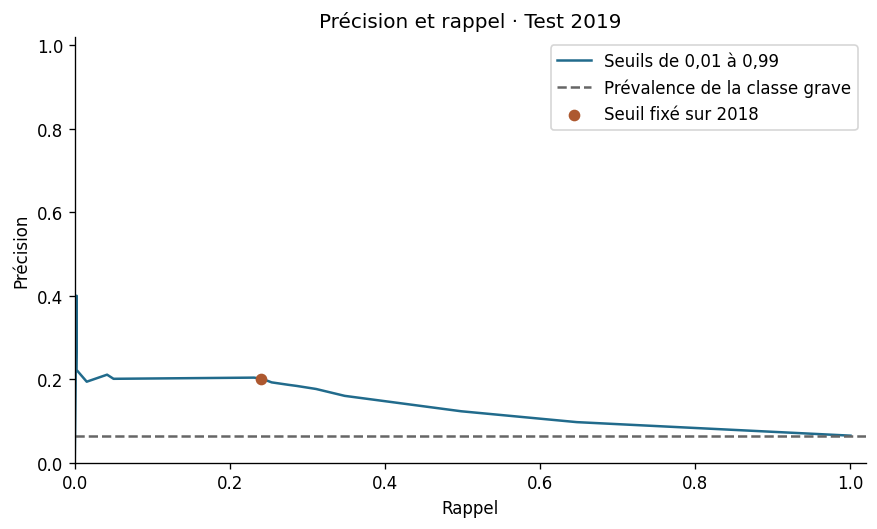

In [19]:
test_preds = scores(pipeline.transform(test)).cache()
assert not test_preds.where(col("prediction") != (col("score_grave") > seuil).cast("double")).limit(1).count()
compte_confusion = {(int(row.label), int(row.prediction)): row["count"]
                    for row in test_preds.groupBy("label", "prediction").count().collect()}
vn, fp, fn, vp = (compte_confusion.get(pair, 0) for pair in [(0,0), (0,1), (1,0), (1,1)])
n_test = vn + fp + fn + vp
assert n_test == repartition[-1]["accidents"]
bilan = {
    "modèle": modele_retenu, "seuil": seuil, "accidents": n_test, "graves": vp + fn,
    "taux_graves": (vp + fn) / n_test, "auc_pr": aire(test_preds, "areaUnderPR"),
    "auc_roc": aire(test_preds, "areaUnderROC"), "precision": vp / (vp + fp) if vp + fp else 0.0,
    "rappel": vp / (vp + fn), "f1": 2 * vp / (2 * vp + fp + fn),
    "exactitude": (vn + vp) / n_test, "exactitude_majoritaire": (vn + fp) / n_test,
    "vrais_negatifs": vn, "fausses_alertes": fp, "cas_manques": fn, "cas_detectes": vp,
}
display(pd.DataFrame([bilan]).round(4).T.rename(columns={0: "Test 2019"}))
matrice = pd.DataFrame([[vn, fp], [fn, vp]], index=["Autre (réel)", "Grave (réel)"],
                      columns=["Autre (prédit)", "Grave (prédit)"])
display(matrice)

courbe_test = lignes_seuils(test_preds.select("label", "score_grave").toPandas())
fig, ax = plt.subplots(figsize=(7.2, 4.3), layout="constrained")
ax.plot(courbe_test["rappel"], courbe_test["precision"], color="#216b8c", label="Seuils de 0,01 à 0,99")
ax.axhline(bilan["taux_graves"], color="#666666", linestyle="--", label="Prévalence de la classe grave")
ax.scatter(bilan["rappel"], bilan["precision"], color="#ad582f", zorder=3, label="Seuil fixé sur 2018")
ax.set(title="Précision et rappel · Test 2019", xlabel="Rappel", ylabel="Précision",
       xlim=(0, 1.02), ylim=(0, 1.02))
ax.legend(loc="upper right")
fig.savefig(OUT / "09_precision_rappel_2019.png", bbox_inches="tight")
plt.show()

### 6.2 Lire les erreurs par condition de lumière

Le taux d’alertes et le rappel peuvent varier avec la lumière. Le tableau affiche les effectifs
pour aider à interpréter les petits groupes. Cette analyse sert à décrire le test 2019. Le seuil
reste commun à tous les groupes et garde la valeur décidée sur 2018.

In [20]:
groupes = test_preds.groupBy("DayNight").agg(
    F.count("*").alias("accidents"), F.sum("label").alias("graves"),
    F.sum("prediction").cast("int").alias("alertes"),
    F.sum((col("label") * col("prediction")).cast("int")).alias("detectes"),
).orderBy(F.desc("accidents")).toPandas()
groupes["part_alertes_pct"] = 100 * groupes["alertes"] / groupes["accidents"]
groupes["rappel_pct"] = 100 * groupes["detectes"] / groupes["graves"].replace(0, np.nan)
assert int(groupes["detectes"].sum()) == vp
display(groupes.round(2))
print(f"Sur {vp + fn:,} accidents graves ou mortels, {vp:,} sont détectés et {fn:,} sont manqués.")
print(f"Le modèle émet {fp:,} fausses alertes au seuil choisi sur 2018.")

,DayNight,accidents,graves,alertes,detectes,part_alertes_pct,rappel_pct
0,Daylight,9930,594.0,711,147,7.16,24.75
1,Night,3034,245.0,295,55,9.72,22.45


Sur 839 accidents graves ou mortels, 202 sont détectés et 637 sont manqués.
Le modèle émet 804 fausses alertes au seuil choisi sur 2018.


## Déploiement

### 7.1 Sauvegarder le pipeline et le contrôler après rechargement

Le `PipelineModel` contient les transformations et le classifieur. On l’applique à cinq
contextes de 2019 dont on retire la cible et les identifiants. On contrôle la prédiction et
le score après rechargement, avec une tolérance numérique de `1e-12` pour le score. Le test
vérifie une réutilisation par lot du modèle dans Spark.

In [21]:
dossier_modele = OUT / "modele_gravite_spark"
pipeline.write().overwrite().save(dossier_modele.resolve().as_uri())
recharge = PipelineModel.load(dossier_modele.resolve().as_uri())

exemples = (test.where("label = 0").orderBy("REPORT_ID").limit(3)
            .unionByName(test.where("label = 1").orderBy("REPORT_ID").limit(2))
            .select(*features).toPandas())
exemples.to_csv(OUT / "exemple_contexte.csv", index=False)
lot = spark.read.options(header=True, mode="FAILFAST").csv((OUT / "exemple_contexte.csv").resolve().as_uri())


def resultat_lot(modele, donnees):
    return (scores(modele.transform(donnees)).select(*features, "score_grave", "prediction")
            .orderBy(*features).toPandas())


avant = resultat_lot(pipeline, lot)
apres = resultat_lot(recharge, lot)
pd.testing.assert_frame_equal(avant, apres, rtol=0, atol=1e-12)
apres.to_csv(OUT / "predictions_gravite.csv", index=False)
(OUT / "metriques_gravite.json").write_text(json.dumps({
    "périodes": repartition, "validation_2018": comparatif,
    "f1_validation_au_seuil": float(meilleur["f1"]), "test_2019": bilan,
}, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
display(apres.round({"score_grave": 4}))

,Time,Month,Day,DayNight,Stats Area,Area Speed,score_grave,prediction
0,01:00 pm,February,Sunday,Daylight,3 Country,110,0.1591,1.0
1,04:10 pm,January,Saturday,Daylight,2 Metropolitan,060,0.0587,0.0
2,10:07 am,February,Sunday,Daylight,2 Metropolitan,060,0.0593,0.0
3,11:15 am,June,Wednesday,Daylight,2 Metropolitan,060,0.0587,0.0
4,12:30 pm,January,Tuesday,Daylight,3 Country,080,0.1226,0.0


### 7.2 Rejouer un lot

Le CSV joint au TP fournit les six colonnes attendues. Le guide indique comment charger
le modèle enregistré et lire `score_grave` et `prediction`. Les scores illustrent la
classification du lot. L’évaluation repose sur l’année 2019 complète. [Guide du TP2](README.md#recharger-le-modèle-fourni)

## Benchmark

### 8.1 Comparer les trois API à un et quatre cœurs

On mesure la requête sans permis, de la construction de la requête à la collecte du petit
tableau agrégé. Dans chaque session locale, les mêmes colonnes d’entrée sont mises en cache
sur huit partitions. Chaque API a un échauffement, puis trois essais en ordre tournant.
Le chronomètre exclut la lecture initiale des CSV, le remplissage du cache et la comparaison
des résultats. Chaque exécution est confrontée au tableau validé dans la section Transformation.

La première comparaison fixe huit partitions de shuffle, désactive l’exécution adaptative
et conserve le seuil de diffusion de 10 Mio des jointures. Le mode `local[1]` offre un thread
de calcul et `local[4]` en offre quatre. Les mesures restent propres à cette machine et à la
taille des tables. [Réglages de performance de Spark](https://spark.apache.org/docs/4.0.1/sql-performance-tuning.html)

In [22]:
version_spark = spark.version
spark.stop()


def entrees_benchmark(session):
    accidents = (lire_dataframe(session, "crash_data").select(
        "REPORT_ID", "Suburb", col("Total Cas").cast("int").alias("Total Cas"))
        .repartition(8, "REPORT_ID").cache())
    unites = (lire_dataframe(session, "units_data").select("REPORT_ID", "Licence Type")
              .repartition(8, "REPORT_ID").cache())
    assert (accidents.count(), unites.count()) == (n_crash, n_units)
    accidents.createOrReplaceTempView("accidents")
    unites.createOrReplaceTempView("unites")
    return accidents, unites


def executions(api):
    # Faire tourner la première API pour varier l’ordre des trois essais.
    for tentative in range(3):
        for nom in api[tentative:] + api[:tentative]:
            yield tentative + 1, nom


def temps_verifie(requete):
    debut = perf_counter()
    mesures = requete().collect()
    temps = perf_counter() - debut
    assert Counter(map(tuple, mesures)) == reference_api
    return temps


api = ["RDD", "DataFrame", "Spark SQL"]
mesures, plans = [], []
for nb_coeurs in (1, 4):
    with demarrer_spark(nb_coeurs) as session:
        session.conf.set("spark.sql.adaptive.enabled", "false")
        session.conf.set("spark.sql.autoBroadcastJoinThreshold", "10485760")
        a, u = entrees_benchmark(session)
        requetes = {"RDD": lambda: sans_permis_rdd(a, u), "DataFrame": lambda: sans_permis_df(a, u),
                    "Spark SQL": lambda: session.sql(SQL_SANS_PERMIS)}
        for requete in requetes.values():
            temps_verifie(requete)
        for numero, nom in executions(api):
            mesures.append({"cœurs": nb_coeurs, "API": nom, "essai": numero,
                           "secondes": temps_verifie(requetes[nom])})
        if nb_coeurs == 4:
            for nom in ("DataFrame", "Spark SQL"):
                flux = StringIO()
                with redirect_stdout(flux):
                    requetes[nom]().explain()
                operateurs = re.findall(r"BroadcastHashJoin|SortMergeJoin|HashAggregate|Exchange", flux.getvalue())
                plans.append((nom, ", ".join(dict.fromkeys(operateurs))))

mesures_pd = pd.DataFrame(mesures)
chronos = mesures_pd.groupby(["API", "cœurs"]).secondes.agg(["median", "min", "max"]).reset_index()
display(chronos.rename(columns={"median": "médiane (s)", "min": "minimum (s)", "max": "maximum (s)"}).round(4))
display(pd.DataFrame(plans, columns=["API", "Opérateurs physiques observés"]))

,API,cœurs,médiane (s),minimum (s),maximum (s)
0,DataFrame,1,0.4207,0.3333,0.4596
1,DataFrame,4,0.2011,0.1627,0.2861
2,RDD,1,8.0635,7.5398,8.1535
3,RDD,4,2.3701,2.3095,2.3719
4,Spark SQL,1,0.4023,0.3451,0.4885
5,Spark SQL,4,0.1564,0.1493,0.1717


,API,Opérateurs physiques observés
0,DataFrame,"HashAggregate, Exchange, BroadcastHashJoin"
1,Spark SQL,"HashAggregate, Exchange, BroadcastHashJoin"


### 8.2 Faire varier les partitions de shuffle

DataFrame et SQL partagent l’optimiseur de Spark. Le plan indique la stratégie de jointure
retenue. Pour observer l’effet des partitions lorsque la jointure peut demander une
redistribution, on fixe quatre cœurs, coupe la diffusion et garde l’exécution adaptative
désactivée. On repartitionne les deux entrées sur des clés différentes de `REPORT_ID` pour
que le plan doive les redistribuer pour joindre. On mesure trois fois après un échauffement
à chaque valeur et on compare les médianes. Le minimum observé vaut pour ce protocole local.

In [23]:
balayage = []
with demarrer_spark(4) as session:
    session.conf.set("spark.sql.adaptive.enabled", "false")
    session.conf.set("spark.sql.autoBroadcastJoinThreshold", "-1")
    a, u = entrees_benchmark(session)
    # Cache à huit partitions avec des clés impropres à la jointure sur REPORT_ID.
    a_shuffle = a.repartition(8, "Suburb").cache()
    u_shuffle = u.repartition(8, "Licence Type").cache()
    assert (a_shuffle.count(), u_shuffle.count()) == (n_crash, n_units)
    requete_shuffle = lambda: sans_permis_df(a_shuffle, u_shuffle)
    for partitions in (4, 8, 32, 128):
        session.conf.set("spark.sql.shuffle.partitions", str(partitions))
        temps_verifie(requete_shuffle)
        durees = [temps_verifie(requete_shuffle) for _ in range(3)]
        balayage.append({"partitions de shuffle": partitions, "médiane (s)": median(durees),
                         "minimum (s)": min(durees), "maximum (s)": max(durees)})

partitions_pd = pd.DataFrame(balayage)
mesures_pd.to_csv(OUT / "benchmark_api.csv", index=False)
partitions_pd.to_csv(OUT / "benchmark_partitions.csv", index=False)
print(f"Spark {version_spark} · résultats identiques pour tous les essais.")
display(partitions_pd.round(4))

Spark 4.0.1 · résultats identiques pour tous les essais.


,partitions de shuffle,médiane (s),minimum (s),maximum (s)
0,4,0.2656,0.2341,0.2849
1,8,0.2456,0.2233,0.3174
2,32,0.3965,0.3483,0.4301
3,128,0.9430,0.8376,0.9528


## Conclusion

- **Données.** Les deux lecteurs retrouvent les mêmes effectifs. Le rapprochement par
  `REPORT_ID` permet de distinguer un accident de chacune de ses unités. Deux requêtes
  produisent les mêmes lignes dans les trois API. Le calcul par accident retient
  **2 053 victimes**, contre 2 072 avec la jointure directe.
- **Analyse.** Le volume culmine à 17 h avec 11 642 accidents. À 2 h, le volume est de
  940 accidents et la part grave ou mortelle atteint son maximum de 9,47 %. La carte regroupe
  123 801 accidents localisés en cellules de 25 km. Une estimation du risque routier par secteur demanderait des
  données d’exposition, par exemple le trafic ou les distances parcourues.
- **Gravité.** Les arbres boostés sont retenus sur 2018. Avec un seuil de 0,14, le test 2019 donne
  une **AUC PR de 0,1352**. Le modèle détecte **202 des 839 cas graves ou mortels**,
  avec 804 fausses alertes. Le pipeline sauvegardé reproduit les prédictions du lot
  de contrôle.
- **Spark.** Les durées dépendent du plan, du nombre de tâches et du travail exécuté dans
  chaque tâche. Les mesures isolent une requête après mise en cache et vérifient l’égalité
  des sorties à chaque essai.